Abdelrahman Hesham

Task 5 - Part 1: Machine Learning models on Spam data and Sentiment data with TF-IDF

In [1]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

nltk.download("stopwords", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("wordnet", quiet=True)

en_stopwords = stopwords.words("english")
en_stopwords.remove("not")
lemmatizer = WordNetLemmatizer()

In [2]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"&lt;|&gt;|&amp;", " ", text)
    text = re.sub(r"[åâ]?£", " pound ", text)
    text = re.sub(r"'", "", text)
    text = re.sub(r"[^\w\s]", " ", text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in en_stopwords]
    return " ".join(tokens)

In [3]:
def evaluate(models, X_train, X_test, y_train, y_test):
    rows = []
    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        rows.append([name, accuracy_score(y_test, y_pred), f1_score(y_test, y_pred, average="macro")])
    return pd.DataFrame(rows, columns=["model", "accuracy", "macro_f1"]).sort_values("accuracy", ascending=False).reset_index(drop=True)

Spam data

In [4]:
spam = pd.read_csv("data/spam.csv", encoding="latin-1")[["v1", "v2"]]
spam.columns = ["label", "message"]
spam = spam.drop_duplicates().reset_index(drop=True)
spam["clean"] = spam["message"].apply(clean_text)
print(spam.shape)
print(spam["label"].value_counts())
spam.head()

(5169, 3)
label
ham     4516
spam     653
Name: count, dtype: int64


,label,message,clean
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,ham,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though


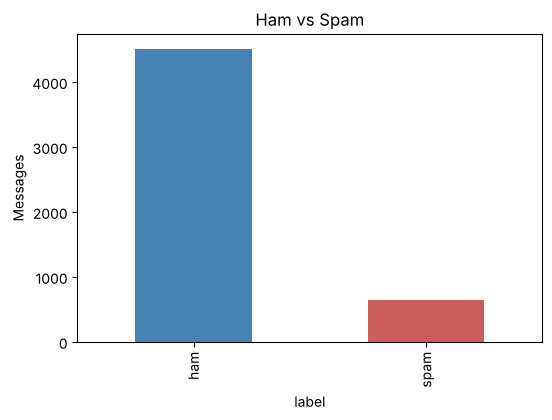

In [5]:
spam["label"].value_counts().plot.bar(color=["steelblue", "indianred"], figsize=(6, 4))
plt.title("Ham vs Spam")
plt.ylabel("Messages")
plt.show()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(spam["clean"], spam["label"], test_size=0.3, random_state=42, stratify=spam["label"])

spam_models = {
    "Logistic Regression": make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000)),
    "Naive Bayes": make_pipeline(TfidfVectorizer(), MultinomialNB()),
    "SVM (SGD)": make_pipeline(TfidfVectorizer(), SGDClassifier(random_state=1)),
}

spam_results = evaluate(spam_models, X_train, X_test, y_train, y_test)
spam_results

,model,accuracy,macro_f1
0,SVM (SGD),0.984526,0.963683
1,Naive Bayes,0.960026,0.895435
2,Logistic Regression,0.953578,0.875930


Improving the accuracy (ideas from Kaggle notebooks)

- use word bigrams with TF-IDF and sublinear tf
- add character n-grams, they catch things like numbers, links and words written in a wrong way (free, fr33, txt)
- class_weight balanced because spam is only 13% of the data
- smaller alpha for Naive Bayes

In [7]:
def word_char_tfidf():
    return make_union(
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2),
    )

spam_models_tuned = {
    "Logistic Regression (tuned)": make_pipeline(word_char_tfidf(), LogisticRegression(C=10, class_weight="balanced", max_iter=2000)),
    "Naive Bayes (tuned)": make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), MultinomialNB(alpha=0.1)),
    "Linear SVM (tuned)": make_pipeline(word_char_tfidf(), LinearSVC(C=1, class_weight="balanced")),
}

spam_results_tuned = evaluate(spam_models_tuned, X_train, X_test, y_train, y_test)
spam_results_tuned

,model,accuracy,macro_f1
0,Logistic Regression (tuned),0.990329,0.977659
1,Linear SVM (tuned),0.989684,0.976008
2,Naive Bayes (tuned),0.982592,0.958860


Logistic Regression (tuned)
              precision    recall  f1-score   support

         ham      0.991     0.998     0.994      1355
        spam      0.984     0.939     0.961       196

    accuracy                          0.990      1551
   macro avg      0.988     0.968     0.978      1551
weighted avg      0.990     0.990     0.990      1551



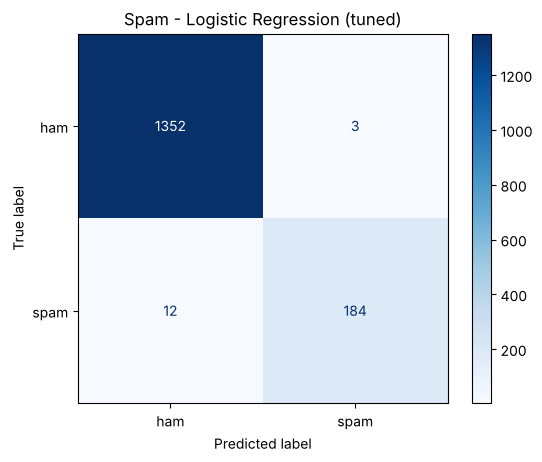

In [8]:
best_spam = spam_models_tuned[spam_results_tuned.loc[0, "model"]]
y_pred = best_spam.predict(X_test)
print(spam_results_tuned.loc[0, "model"])
print(classification_report(y_test, y_pred, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["ham", "spam"]).plot(cmap="Blues")
plt.title("Spam - " + spam_results_tuned.loc[0, "model"])
plt.show()

Sentiment data (book reviews)

In [9]:
reviews = pd.read_csv("data/book_reviews_sample.csv")

def rating_to_label(r):
    if r <= 2:
        return "negative"
    elif r == 3:
        return "neutral"
    return "positive"

reviews["label"] = reviews["rating"].apply(rating_to_label)
reviews["clean"] = reviews["reviewText"].apply(clean_text)
print(reviews["label"].value_counts())
reviews.head()

label
positive    46
negative    37
neutral     17
Name: count, dtype: int64


,index,reviewText,rating,label,clean
0,11494,Clean and funny. A bit busy with all the diffe...,3,neutral,clean funny bit busy different plot going over...
1,984,Alex a sexy hot cop and the PhD candidate. Wha...,4,positive,alex sexy hot cop phd candidate match make gre...
2,1463,Good thing that this is a free story. I read i...,1,negative,good thing free story read year ago not worth ...
3,10342,"Action, action, action! Equipment keeps gettin...",4,positive,action action action equipment keep getting bl...
4,5256,this was hands down the worse book i have ever...,1,negative,hand worse book ever read trst say alot


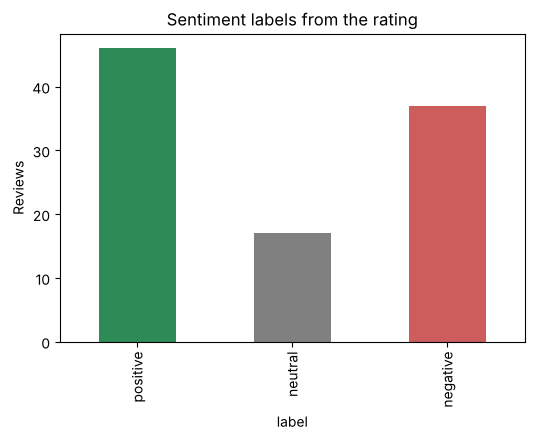

In [10]:
reviews["label"].value_counts().reindex(["positive", "neutral", "negative"]).plot.bar(color=["seagreen", "gray", "indianred"], figsize=(6, 4))
plt.title("Sentiment labels from the rating")
plt.ylabel("Reviews")
plt.show()

In [11]:
X_train, X_test, y_train, y_test = train_test_split(reviews["clean"], reviews["label"], test_size=0.3, random_state=42, stratify=reviews["label"])

sent_models = {
    "Logistic Regression": make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000)),
    "Naive Bayes": make_pipeline(TfidfVectorizer(), MultinomialNB()),
    "SVM (SGD)": make_pipeline(TfidfVectorizer(), SGDClassifier(random_state=1)),
}

sent_results = evaluate(sent_models, X_train, X_test, y_train, y_test)
sent_results

,model,accuracy,macro_f1
0,Logistic Regression,0.633333,0.458002
1,Naive Bayes,0.633333,0.458002
2,SVM (SGD),0.633333,0.540693


The data is only 100 reviews, so 30 test reviews is very small and the score changes a lot with the split. Here I use 5-fold cross validation to get a more stable score, and try the same improvements.

In [12]:
sent_models_tuned = {
    "Logistic Regression (tuned)": make_pipeline(word_char_tfidf(), LogisticRegression(C=10, class_weight="balanced", max_iter=2000)),
    "Naive Bayes (tuned)": make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), ComplementNB(alpha=0.3)),
    "Linear SVM (tuned)": make_pipeline(word_char_tfidf(), LinearSVC(C=0.5, class_weight="balanced")),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in {**sent_models, **sent_models_tuned}.items():
    scores = cross_val_score(model, reviews["clean"], reviews["label"], cv=cv, scoring="accuracy")
    rows.append([name, scores.mean(), scores.std()])

sent_cv = pd.DataFrame(rows, columns=["model", "cv_accuracy", "std"]).sort_values("cv_accuracy", ascending=False).reset_index(drop=True)
sent_cv

,model,cv_accuracy,std
0,Naive Bayes,0.70,0.054772
1,Logistic Regression,0.69,0.066332
2,Linear SVM (tuned),0.67,0.074833
3,Naive Bayes (tuned),0.67,0.107703
4,Logistic Regression (tuned),0.66,0.086023
5,SVM (SGD),0.62,0.087178


Comparison of all results

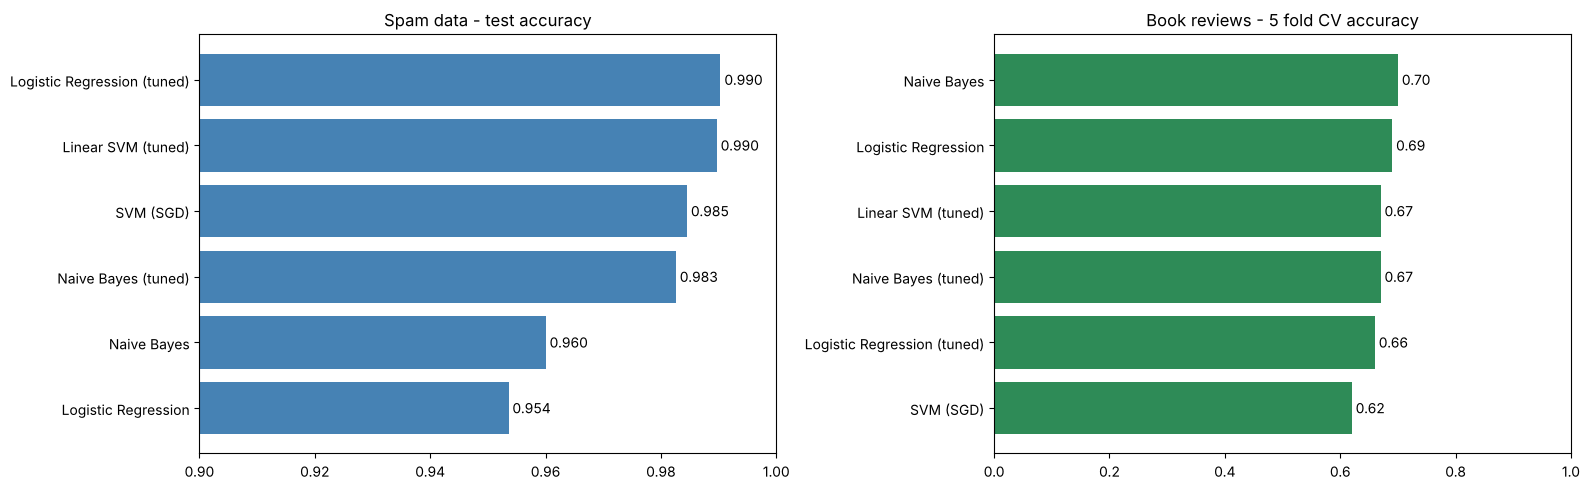

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

spam_all = pd.concat([spam_results, spam_results_tuned]).sort_values("accuracy")
ax[0].barh(spam_all["model"], spam_all["accuracy"], color="steelblue")
ax[0].set_xlim(0.9, 1)
ax[0].set_title("Spam data - test accuracy")
for i, v in enumerate(spam_all["accuracy"]):
    ax[0].text(v, i, f" {v:.3f}", va="center")

sent_sorted = sent_cv.sort_values("cv_accuracy")
ax[1].barh(sent_sorted["model"], sent_sorted["cv_accuracy"], color="seagreen")
ax[1].set_xlim(0, 1)
ax[1].set_title("Book reviews - 5 fold CV accuracy")
for i, v in enumerate(sent_sorted["cv_accuracy"]):
    ax[1].text(v, i, f" {v:.2f}", va="center")

plt.tight_layout()
plt.show()

In [14]:
summary = pd.DataFrame({
    "Spam - best ML model": [spam_results_tuned.loc[0, "model"], round(spam_results_tuned.loc[0, "accuracy"], 3)],
    "Reviews - best ML model": [sent_cv.loc[0, "model"], round(sent_cv.loc[0, "cv_accuracy"], 3)],
    "Reviews - best transformer (task 4)": ["twitter-roberta", 0.85],
}, index=["model", "accuracy"]).T
summary

,model,accuracy
Spam - best ML model,Logistic Regression (tuned),0.99
Reviews - best ML model,Naive Bayes,0.7
Reviews - best transformer (task 4),twitter-roberta,0.85


Notes

- On spam data all models are above 95%, adding character n-grams and class_weight gives the best result.
- On book reviews the ML models are much weaker because there are only 100 reviews and 3 classes, the pretrained transformer from task 4 (85%) is much better than training from scratch on this small data.